# BME 574 — Project 4 explained
### Three things the CNN lecture did not cover, and the project is graded on

The MNIST notebook gave you the convolution: what the kernel does, why it is cheap, and the
permutation experiment showing that the architecture is an *assumption* rather than a generically
better layer. This notebook is about what changes when the images are medical.

1. **You now have three splits, not two.** Validation is for choosing; test is for reporting. Using
   the test set to pick when to stop training is the most common way to publish a number that does
   not hold up.
2. **Augmentation is a claim about your modality.** "Flipping does not change the label" is a
   statement about anatomy and acquisition, not about machine learning, and it is false for some of
   the tracks in this project.
3. **A good test score does not mean the model generalises.** Your test images came from the same
   collection as your training images. The clinic is a different collection.

Read it top to bottom and run every cell — about 25 minutes. Nothing to hand in. It runs on
`demo.npz`, so it finishes in a couple of minutes.

In [1]:
import copy
import os

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

plt.rcParams.update({'font.size': 9, 'figure.dpi': 120})
np.set_printoptions(precision=4, suppress=True)
SEED = 0


def load_bundle(path):
    z = np.load(path, allow_pickle=True)
    b = {k: z[k] for k in z.files}
    for k in ('track', 'split_kind', 'source', 'notes', 'license'):
        b[k] = str(b[k])
    b['class_names'] = [str(s) for s in b['class_names']]
    b['n_channels'] = int(b['n_channels'])
    return b


BUNDLE = 'bundles_p4/demo.npz'
if not os.path.exists(BUNDLE):
    raise SystemExit(
        '%s not found.\n'
        'Run this notebook from the folder that contains bundles_p4/, or copy\n'
        'bundles_p4/demo.npz next to it.' % BUNDLE)

B = load_bundle(BUNDLE)
X_u8, y_np = B['X'], B['y']
tr_i, va_i, te_i = B['train_idx'], B['val_idx'], B['test_idx']
CLASSES, K, CH = B['class_names'], len(B['class_names']), B['n_channels']

Xf = torch.tensor(X_u8, dtype=torch.float32) / 255.0
y = torch.tensor(y_np, dtype=torch.long)
MU = Xf[tr_i].mean(dim=(0, 2, 3), keepdim=True)
SD = Xf[tr_i].std(dim=(0, 2, 3), keepdim=True)
Xf = (Xf - MU) / SD
Xtr, ytr = Xf[tr_i], y[tr_i]
Xva, yva = Xf[va_i], y[va_i]
Xte, yte = Xf[te_i], y[te_i]

print('track   :', B['track'])
print('images  :', X_u8.shape, '->', CH, 'channels,', K, 'classes')
print('split   : %d train / %d val / %d test' % (len(tr_i), len(va_i), len(te_i)))

track   : demo
images  : (3000, 3, 28, 28) -> 3 channels, 6 classes
split   : 2100 train / 300 val / 600 test


In [2]:
def build_cnn(n_channels, n_classes, p_drop=0.25, seed=SEED):
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Conv2d(n_channels, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Dropout(p_drop), nn.Linear(32 * 7 * 7, n_classes))


def evaluate(model, Xe, ye, lossfn=None, batch=1000):
    model.eval()
    with torch.no_grad():
        lg = torch.cat([model(Xe[i:i + batch]) for i in range(0, len(Xe), batch)])
    return (float((lg.argmax(1) == ye).double().mean()), lg.argmax(1),
            float(lossfn(lg, ye)) if lossfn is not None else float('nan'))


def train(model, Xa, ya, Xv, yv, epochs=15, lr=1e-3, batch=128, augment=None,
          seed=SEED, select_on='val', Xt=None, yt=None):
    loader = DataLoader(TensorDataset(Xa, ya), batch_size=batch, shuffle=True,
                        generator=torch.Generator().manual_seed(seed + 100))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lf = nn.CrossEntropyLoss()
    hist, best, best_state, best_ep = [], -1.0, None, -1
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            if augment is not None:
                xb = augment(xb)
            opt.zero_grad(); lf(model(xb), yb).backward(); opt.step()
        a_tr, _, l_tr = evaluate(model, Xa, ya, lf)
        a_va, _, l_va = evaluate(model, Xv, yv, lf)
        a_te = evaluate(model, Xt, yt)[0] if Xt is not None else np.nan
        hist.append((l_tr, l_va, a_tr, a_va, a_te))
        score = a_te if select_on == 'test' else a_va
        if score > best:
            best, best_ep = score, ep
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return np.array(hist), best_ep


print('helpers ready')

helpers ready


---
# 1 · Three splits, and what each one is for

| split | you may use it to | you may not |
|---|---|---|
| **train** | fit the weights | — |
| **validation** | choose anything: epochs, width, learning rate, augmentation | report it as your result |
| **test** | report, once, at the end | choose anything |

The rule has one sentence behind it: **every time you look at a set and change something, you fit
to it a little.** The test set only measures generalisation while it is untouched.

"Choosing when to stop training" is a hyperparameter like any other. Below, the same model is
trained twice from the same seed; the only difference is which split picks the epoch to keep.

In [3]:
# Selecting on the test set biases the reported number UPWARD in expectation.
# A single run may show nothing, so run several seeds and look at the average.
print('%6s %22s %22s %10s' % ('seed', 'kept best VALIDATION', 'kept best TEST', 'gap'))
print('-' * 64)
gaps = []
for s in range(5):
    mv = build_cnn(CH, K, seed=s)
    hs, e_v = train(mv, Xtr, ytr, Xva, yva, Xt=Xte, yt=yte, select_on='val', seed=s)
    a_v = evaluate(mv, Xte, yte)[0]
    mt = build_cnn(CH, K, seed=s)
    _, e_t = train(mt, Xtr, ytr, Xva, yva, Xt=Xte, yt=yte, select_on='test', seed=s)
    a_t = evaluate(mt, Xte, yte)[0]
    gaps.append(a_t - a_v)
    print('%6d %12d %9.4f %12d %9.4f %10s'
          % (s, e_v + 1, a_v, e_t + 1, a_t, '%+.4f' % (a_t - a_v)))
    if s == 0:
        h, ep_val, ep_test, m_val = hs, e_v, e_t, mv   # kept for the figures below

gaps = np.array(gaps)
print('-' * 64)
print('mean gap %+.4f   (never negative, because picking the maximum of %d test'
      % (gaps.mean(), len(h)))
print('         evaluations cannot do worse than picking one of them blind)')
print()
print('The size of the gap is not the lesson - on this easy stand-in it is small, and')
print('on a harder dataset it is larger. The lesson is that the second column is not')
print('an estimate of anything. It is the MAXIMUM of %d noisy test evaluations, and' % len(h))
print('the maximum of a noisy sequence sits above the mean whether or not the model')
print('underneath it is any better.')

  seed   kept best VALIDATION         kept best TEST        gap
----------------------------------------------------------------


     0           15    0.9900           14    0.9900    +0.0000


     1           15    0.9517           15    0.9517    +0.0000


     2           14    0.9433           13    0.9533    +0.0100


     3           15    0.9900           15    0.9900    +0.0000


     4           15    0.9933           15    0.9933    +0.0000
----------------------------------------------------------------
mean gap +0.0020   (never negative, because picking the maximum of 15 test
         evaluations cannot do worse than picking one of them blind)

The size of the gap is not the lesson - on this easy stand-in it is small, and
on a harder dataset it is larger. The lesson is that the second column is not
an estimate of anything. It is the MAXIMUM of 15 noisy test evaluations, and
the maximum of a noisy sequence sits above the mean whether or not the model
underneath it is any better.


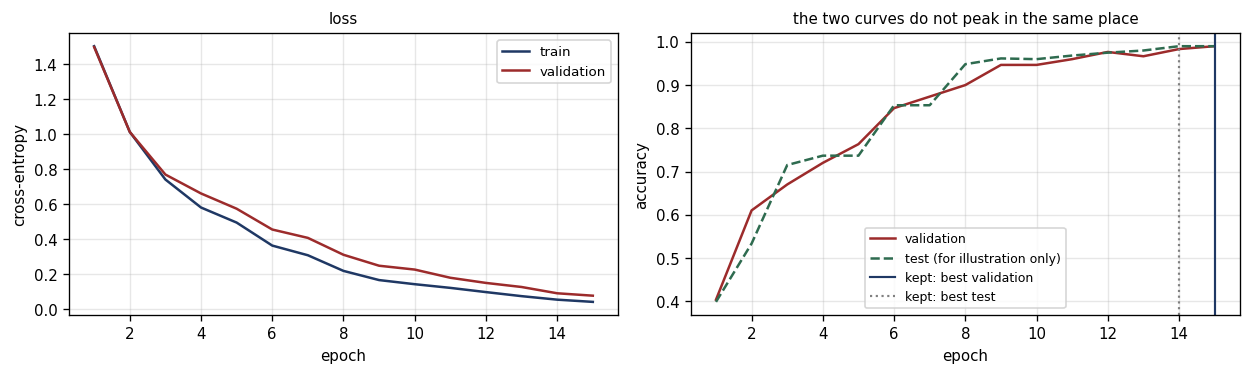

In [4]:
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2))
ax[0].plot(ep, h[:, 0], color='#1F3864', label='train')
ax[0].plot(ep, h[:, 1], color='#9C2B2B', label='validation')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('cross-entropy'); ax[0].legend(fontsize=8)
ax[0].set_title('loss', fontsize=9); ax[0].grid(alpha=.3)

ax[1].plot(ep, h[:, 3], color='#9C2B2B', label='validation')
ax[1].plot(ep, h[:, 4], color='#2E6B4F', ls='--', label='test (for illustration only)')
ax[1].axvline(ep_val + 1, color='#1F3864', lw=1.3, label='kept: best validation')
ax[1].axvline(ep_test + 1, color='grey', ls=':', lw=1.3, label='kept: best test')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('accuracy'); ax[1].legend(fontsize=7.5)
ax[1].set_title('the two curves do not peak in the same place', fontsize=9); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

The green curve is drawn here only to make the point. **In your project the test accuracy is
computed once, after the model is finished.** If you find yourself re-running a cell because the
test number was disappointing, you have started using the test set to choose, and the number you
eventually report is no longer the thing you think it is.

---
# 2 · Augmentation is a claim about your images

Augmentation shows the network transformed copies of the training images **with the label
unchanged**. That is a factual claim: *this transformation does not alter what the image is of.*

Whether the claim is true depends entirely on the modality.

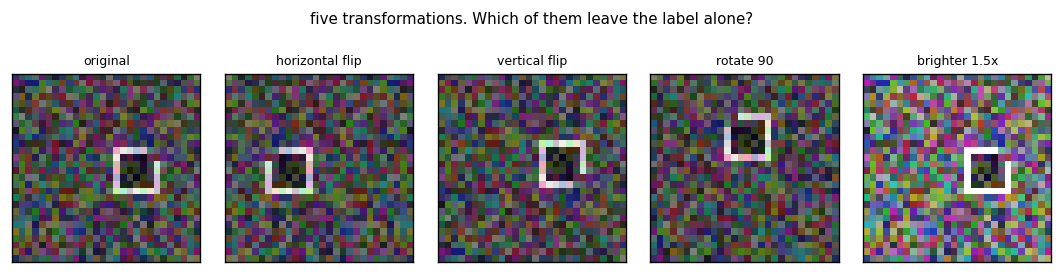

For THIS stand-in the class is the size of the patch and whether it is hollow,
and none of flips or rotations change either -- so all four are legitimate.
Brightness is legitimate too, because colour carries no information here.

For your real track the answers are different, and that is the exercise.


In [5]:
def show_row(ax_row, imgs, titles):
    for a, im, t in zip(ax_row, imgs, titles):
        a.imshow(im[0], cmap='gray') if CH == 1 else a.imshow(im.transpose(1, 2, 0))
        a.set_title(t, fontsize=7.5); a.set_xticks([]); a.set_yticks([])

src = X_u8[tr_i[3]]
variants = [src,
            src[:, :, ::-1].copy(),
            src[:, ::-1, :].copy(),
            np.rot90(src, 1, axes=(1, 2)).copy(),
            np.clip(src.astype(int) * 1.5, 0, 255).astype(np.uint8)]
names = ['original', 'horizontal flip', 'vertical flip', 'rotate 90', 'brighter 1.5x']
fig, ax = plt.subplots(1, 5, figsize=(9, 2.1))
show_row(ax, variants, names)
fig.suptitle('five transformations. Which of them leave the label alone?', y=1.06, fontsize=9)
plt.tight_layout(); plt.show()

print('For THIS stand-in the class is the size of the patch and whether it is hollow,')
print('and none of flips or rotations change either -- so all four are legitimate.')
print('Brightness is legitimate too, because colour carries no information here.')
print()
print('For your real track the answers are different, and that is the exercise.')

### The three tracks, and the answers that are not obvious

**Blood — peripheral smear microscopy.** Cells are cropped and centred, and a cell on a slide has
no up. Horizontal flip, vertical flip, and all four rotations are free. Small translations too.
This is the easy case, and the augmentation budget here is generous.

**Derma — dermatoscopic images of skin lesions.** Orientation is free for the same reason. But the
ABCD rule that dermatologists use — Asymmetry, Border, **Colour**, Diameter — tells you that colour
and size carry diagnosis. A brightness or hue jitter that would be harmless on natural photographs
can move a lesion across a diagnostic boundary here, and a random crop or resize changes apparent
diameter. Geometry yes; photometry with care.

**Organ — abdominal CT.** CT has a canonical orientation, and this is the track where a careless
augmenter does real damage: two of the eleven classes are **femur-left** and **femur-right**. A
horizontal flip turns one into the other while leaving the label alone, so you are not augmenting,
you are **feeding the network mislabelled data**. Small translations and mild intensity scaling are
defensible; mirroring is not.

> The general form: an augmentation is valid when the transformed image could plausibly have come
> out of the same scanner, of the same patient, with the same label. Ask that question literally.

In [6]:
# what mislabelling-by-augmentation does, made concrete
A, Bc = 0, 1          # pretend these two classes are mirror images of each other, as
                      # femur-left and femur-right are on the organ track
mask = np.isin(y_np[tr_i], [A, Bc])
print('Suppose classes "%s" and "%s" were mirror images of each other.'
      % (CLASSES[A], CLASSES[Bc]))
print('A horizontal flip applied to %d of the %d training images would then produce'
      % (mask.sum(), len(tr_i)))
print('images of class %d labelled %d, and vice versa -- %.0f%% of your training set'
      % (A, Bc, 100 * mask.mean()))
print('carrying a label that contradicts the picture.')
print()
print('The model does not crash. It learns that the two classes are interchangeable,')
print('and its confusion matrix shows exactly that: a clean 50/50 block.')

Suppose classes "solid 5px" and "solid 7px" were mirror images of each other.
A horizontal flip applied to 724 of the 2100 training images would then produce
images of class 0 labelled 1, and vice versa -- 34% of your training set
carrying a label that contradicts the picture.

The model does not crash. It learns that the two classes are interchangeable,
and its confusion matrix shows exactly that: a clean 50/50 block.


---
# 3 · A good test score is not generalisation

Your test images were collected in the same study, on the same instruments, prepared by the same
people, as your training images. A held-out split from that collection answers one question:

> *If I saw more images from this same collection, would the model still work?*

That is worth knowing and it is not the clinical question, which is:

> *If I installed this in a different hospital, would it still work?*

The second question needs data from a different source — which is why the organ track ships one:
the same eleven organs, imaged in a **different anatomical plane**. Here is the effect in
miniature: the model is scored on the ordinary test set, and then on the same test images
re-oriented. Nothing has been added or removed; only the presentation has changed.

In [7]:
def reorient(Z, seed=1234):
    g = torch.Generator().manual_seed(seed)
    out = Z.clone()
    k = torch.randint(0, 4, (len(Z),), generator=g)
    flip = torch.rand(len(Z), generator=g) < 0.5
    for j in range(1, 4):
        sel = k == j
        if sel.any():
            out[sel] = torch.rot90(out[sel], j, dims=[2, 3])
    out[flip] = torch.flip(out[flip], dims=[3])
    return out


def make_aug(seed=SEED):
    g = torch.Generator().manual_seed(seed + 7)
    def augment(xb):
        xb = xb.clone()
        n = len(xb)
        s = torch.rand(n, generator=g) < 0.5
        xb[s] = torch.flip(xb[s], dims=[3])
        s = torch.rand(n, generator=g) < 0.5
        xb[s] = torch.flip(xb[s], dims=[2])
        s = torch.rand(n, generator=g) < 0.5
        if s.any():
            xb[s] = torch.rot90(xb[s], int(torch.randint(1, 4, (1,), generator=g)), dims=[2, 3])
        return xb
    return augment


m_aug = build_cnn(CH, K)
train(m_aug, Xtr, ytr, Xva, yva, augment=make_aug())

Xte_r = reorient(Xte)
rows = [('no augmentation', m_val), ('flips + rotations', m_aug)]
print('%-22s %16s %18s %10s' % ('training', 'ordinary test', 're-oriented test', 'drop'))
print('-' * 70)
res = {}
for name, m in rows:
    a0 = evaluate(m, Xte, yte)[0]
    a1 = evaluate(m, Xte_r, yte)[0]
    res[name] = (a0, a1)
    print('%-22s %16.4f %18.4f %+10.4f' % (name, a0, a1, a1 - a0))

training                  ordinary test   re-oriented test       drop
----------------------------------------------------------------------
no augmentation                  0.9900             0.9833    -0.0067


flips + rotations                0.9950             0.9933    -0.0017


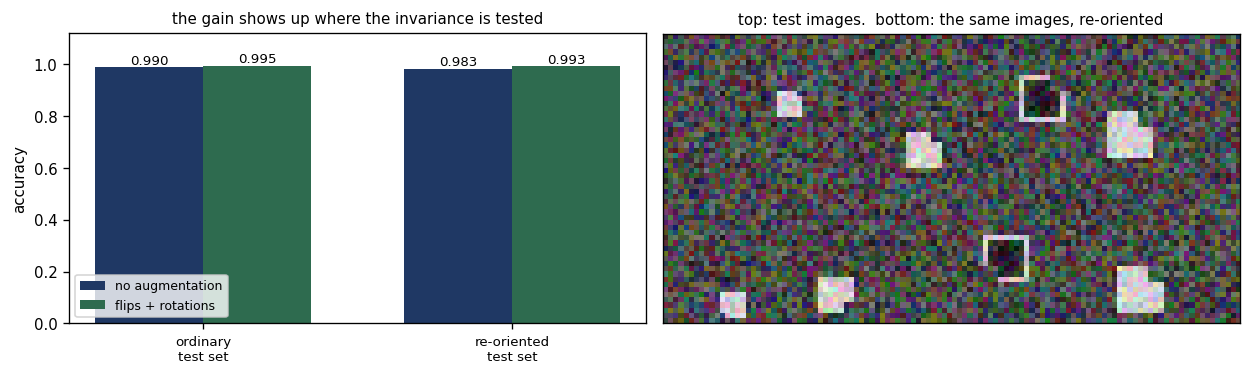

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2))
w, xs = 0.35, np.arange(2)
ax[0].bar(xs - w / 2, res['no augmentation'], w, color='#1F3864', label='no augmentation')
ax[0].bar(xs + w / 2, res['flips + rotations'], w, color='#2E6B4F', label='flips + rotations')
for i in range(2):
    ax[0].text(i - w / 2, res['no augmentation'][i] + .012,
               '%.3f' % res['no augmentation'][i], ha='center', fontsize=8)
    ax[0].text(i + w / 2, res['flips + rotations'][i] + .012,
               '%.3f' % res['flips + rotations'][i], ha='center', fontsize=8)
ax[0].set_xticks(xs); ax[0].set_xticklabels(['ordinary\ntest set', 're-oriented\ntest set'],
                                            fontsize=8)
ax[0].set_ylim(0, 1.12); ax[0].set_ylabel('accuracy'); ax[0].legend(fontsize=7.5)
ax[0].set_title('the gain shows up where the invariance is tested', fontsize=9)

idx = [0, 1, 2, 3]
strip = np.hstack([(Xte[i] * SD[0] + MU[0]).clamp(0, 1).permute(1, 2, 0).numpy()
                   if CH == 3 else (Xte[i] * SD[0] + MU[0]).clamp(0, 1)[0].numpy()
                   for i in idx])
strip_r = np.hstack([(Xte_r[i] * SD[0] + MU[0]).clamp(0, 1).permute(1, 2, 0).numpy()
                     if CH == 3 else (Xte_r[i] * SD[0] + MU[0]).clamp(0, 1)[0].numpy()
                     for i in idx])
ax[1].imshow(np.vstack([strip, strip_r]) if CH == 3 else
             np.vstack([strip, strip_r]), cmap=None if CH == 3 else 'gray')
ax[1].set_xticks([]); ax[1].set_yticks([])
ax[1].set_title('top: test images.  bottom: the same images, re-oriented', fontsize=9)
plt.tight_layout(); plt.show()

The unaugmented model is worse on the re-oriented images even though they are *the same
specimens*. It had quietly learned the orientation of the training set along with everything else.

That is the shape of almost every medical-imaging generalisation failure that has been written up:
the model learns something real about the collection that is not the thing you wanted. Scanner
model, exposure settings, which hospital, a radiologist's annotation burned into the corner, the
orientation convention of a technician. It is not that the model cheated — it used the most
reliable signal available, and in your collection that signal was reliable.

**Augmentation is one defence**: it makes a nuisance variable unreliable on purpose, so the network
has to look past it. It only works for nuisances you thought of, which is why Step 4 of the project
asks you to write the list down and defend it.

---
## What to carry into the project

| | The rule | Where it bites |
|---|---|---|
| **1** | Choose on validation, report on test, once | Step 2 and the memo |
| **2** | Normalise with the **training** mean and sd, per channel | Step 0 |
| **3** | Every augmentation is a claim about the modality — write the list and defend it | Step 4 |
| **4** | The test set and the clinic are different questions | Step 5 and memo Q4 |
| **5** | If the CNN does not beat a dense net, or shrugs off a pixel permutation, say so | Step 3 |

Now open **`BME574_Project4_starter.ipynb`**.